# [GSE166142](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE166142)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-09-12
> - Modified: 2025-02-23

# 1. Experimental Design

> Nucleolus assembly impairment leads to two-cell transcriptional repression via NPM1-mediated PRC2 recruitment.
> - Li, D., Cao, R., Li, Q. et al. Nucleolus assembly impairment leads to two-cell transcriptional repression via NPM1-mediated PRC2 recruitment. Nat Struct Mol Biol 30, 914–925 (2023). https://doi.org/10.1038/s41594-023-01003-w.
> - polyA RNA-seq
> - Illumina NovaSeq 6000, PE150
> - mm10

| Sample | Organism | Strain | Tissue | Treatment | Time | Replicate |
| - | - | - | - | - | - | - |
| LoNA-Ctrl | Mus musculus | C57BL/6 | Embryos | Control | 18, 20, 22, 24h | rep1~4 |
| LoNA-KO | Mus musculus | C57BL/6  | Embryos | LoNA KO | 18, 20, 22, 24h | rep1~4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_LoNA_GSE166142/04_output"

### a). FeatureCounts

In [ ]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^04_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _)

dim(raw_counts)

In [4]:
coldata <- colnames(raw_counts) |> 
    tibble(sample = _) |> 
    filter(str_detect(sample, fixed("EM"))) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("Ctrl", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    column_to_rownames("sample")

head(coldata)

,Cell,Gene,Group,Time,Replicate
,<chr>,<chr>,<fct>,<fct>,<fct>
Ctrl_18h_rep1,EM,LoNA,Ctrl,18h,rep1
Ctrl_18h_rep2,EM,LoNA,Ctrl,18h,rep2
Ctrl_18h_rep3,EM,LoNA,Ctrl,18h,rep3
Ctrl_18h_rep4,EM,LoNA,Ctrl,18h,rep4
Ctrl_20h_rep1,EM,LoNA,Ctrl,20h,rep1
Ctrl_20h_rep2,EM,LoNA,Ctrl,20h,rep2


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("EM")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Time + Group)

class: DESeqDataSet 
dim: 55335 32 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(5): Cell Gene Group Time Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName), 
        Group = factor(Group, levels = c("Ctrl", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Time", "Replicate") |>
    as.data.frame()

In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Time + Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 32 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(5): Cell Gene Group Time Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("Ctrl", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Time + Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 32 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(5): Cell Gene Group Time Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_[^_]+_", "", names), 
        Group = factor(Group, levels = c("Ctrl", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    select("names", "files", "Cell", "Gene", "Group", "Time", "Replicate") |>
    as.data.frame()

In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE



Error in download.file(url, destfile, quiet = TRUE) : 
  cannot open URL 'https://hgdownload.soe.ucsc.edu/goldenPath/mm10/database/chromInfo.txt.gz'


loading existing TxDb created: 2026-06-23 05:16:20

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene mapping from database

generating gene ranges

assignRanges='range': gene ranges assigned by total range of isoforms
  see details at: ?summarizeToGene,SummarizedExperiment-method

summarizing abundance

summarizing counts

summarizing length



In [20]:
DESeqDataSet(gse, design = ~ Time + Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 32 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(6): names Cell ... Time Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("Ctrl", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Time + Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 32 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(5): Cell Gene Group Time Replicate

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 32 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(5): Cell Gene Group Time Replicate

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Time + Group)

dds

class: DESeqDataSet 
dim: 55335 32 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(32): Ctrl_18h_rep1 Ctrl_18h_rep2 ... KO_24h_rep3 KO_24h_rep4
colData names(5): Cell Gene Group Time Replicate

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 4
# keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 20054 
 Remove: 35281 
 Retention rate: 36.24 %


In [29]:
design <- model.matrix(~ Time + Group, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18180 
 Remove: 37155 
 Retention rate: 32.85 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [32]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [33]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [34]:
vsd <- vst(dds, blind = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


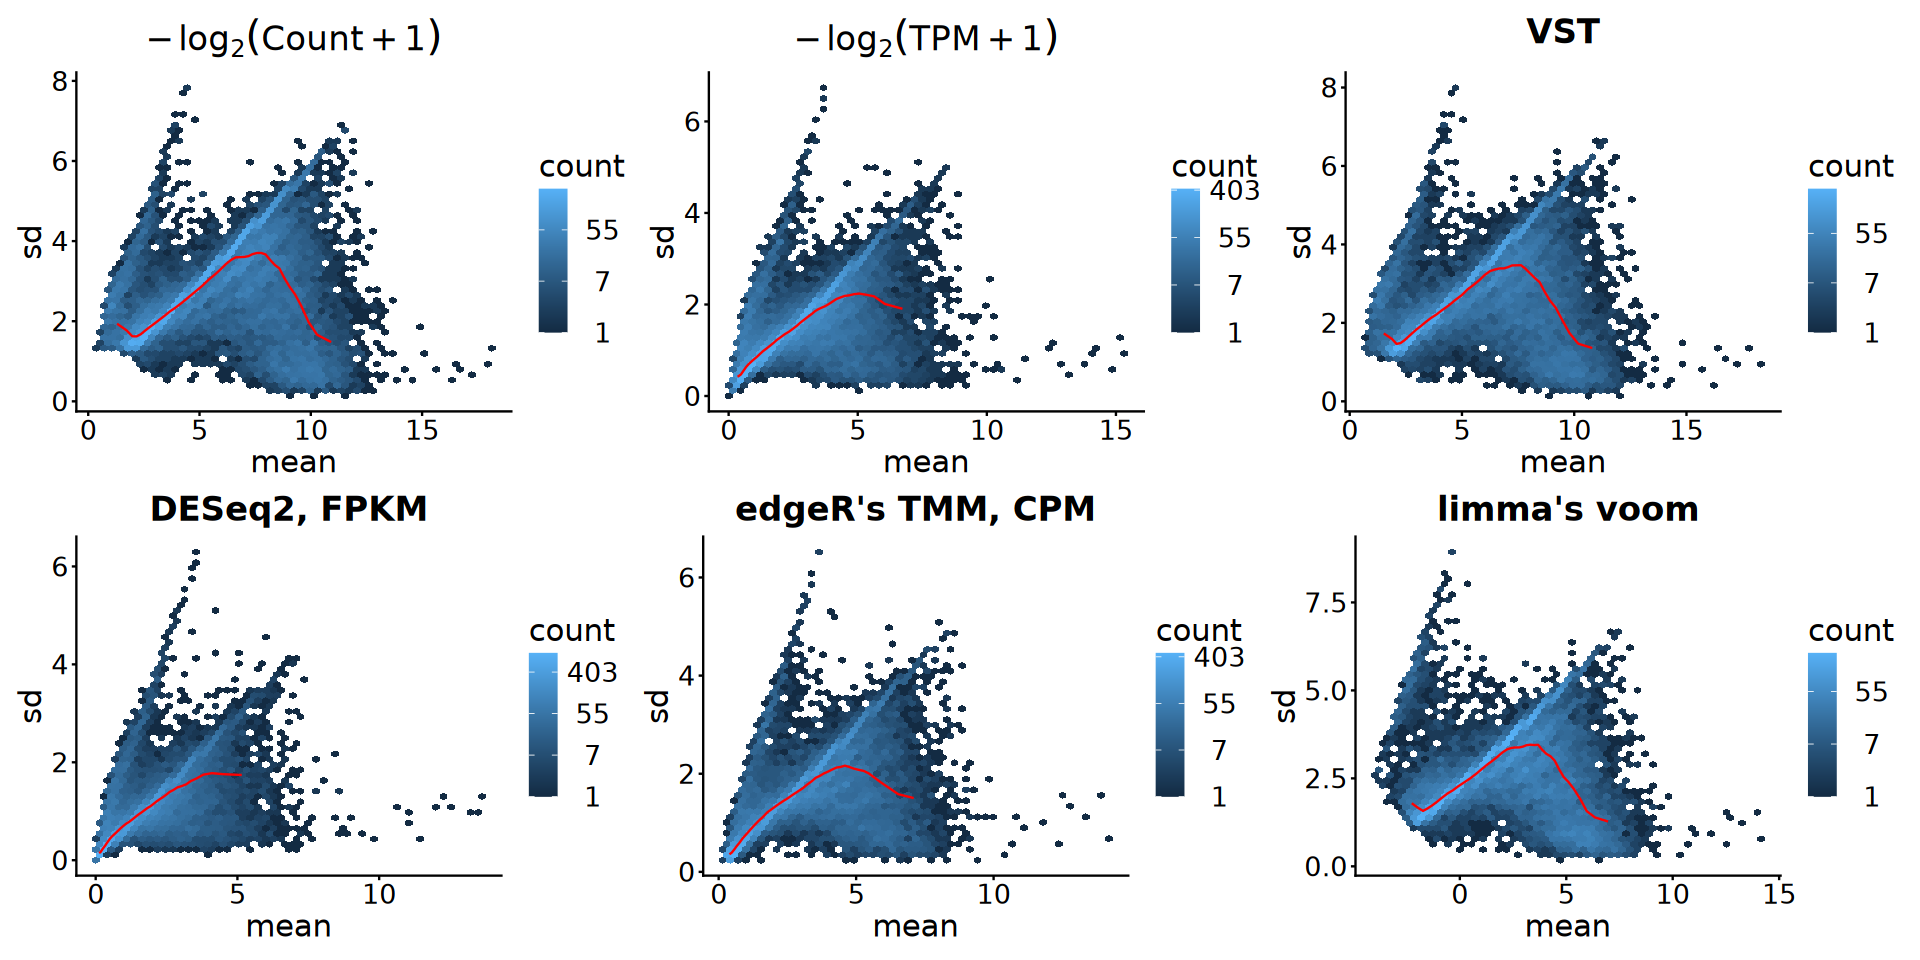

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(vsd)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Time, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

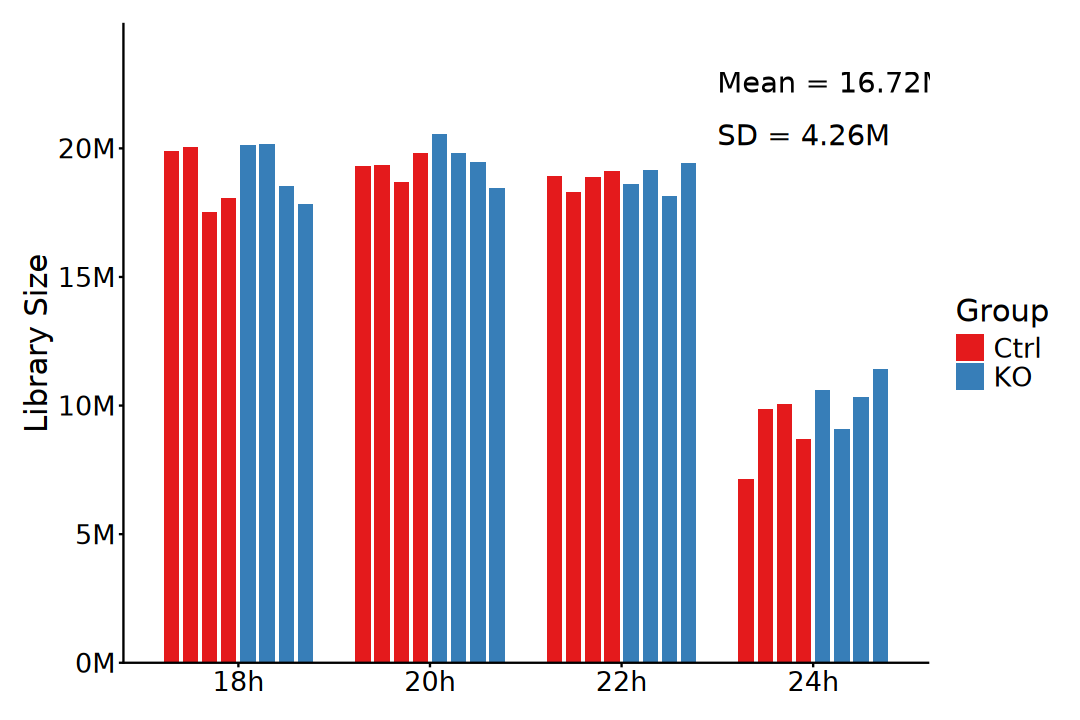

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Time, y = librarySize)) +
    geom_col(
        aes(fill = Group, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = TRUE) +
    annotate(
        geom = "text", x = 3.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 3.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set1") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [42]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [43]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [44]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    # geom_smooth(
    #     formula = "y ~ x", method = "loess", se = FALSE,
    #     color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [45]:
pca_res <- plotPCA(
    vsd, intgroup = c("Group", "Time", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [46]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    # geom_smooth(
    #     formula = "y ~ x", method = "loess", se = FALSE,
    #     color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for VST", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [47]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [48]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    # geom_smooth(
    #     formula = "y ~ x", method = "loess", se = FALSE,
    #     color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

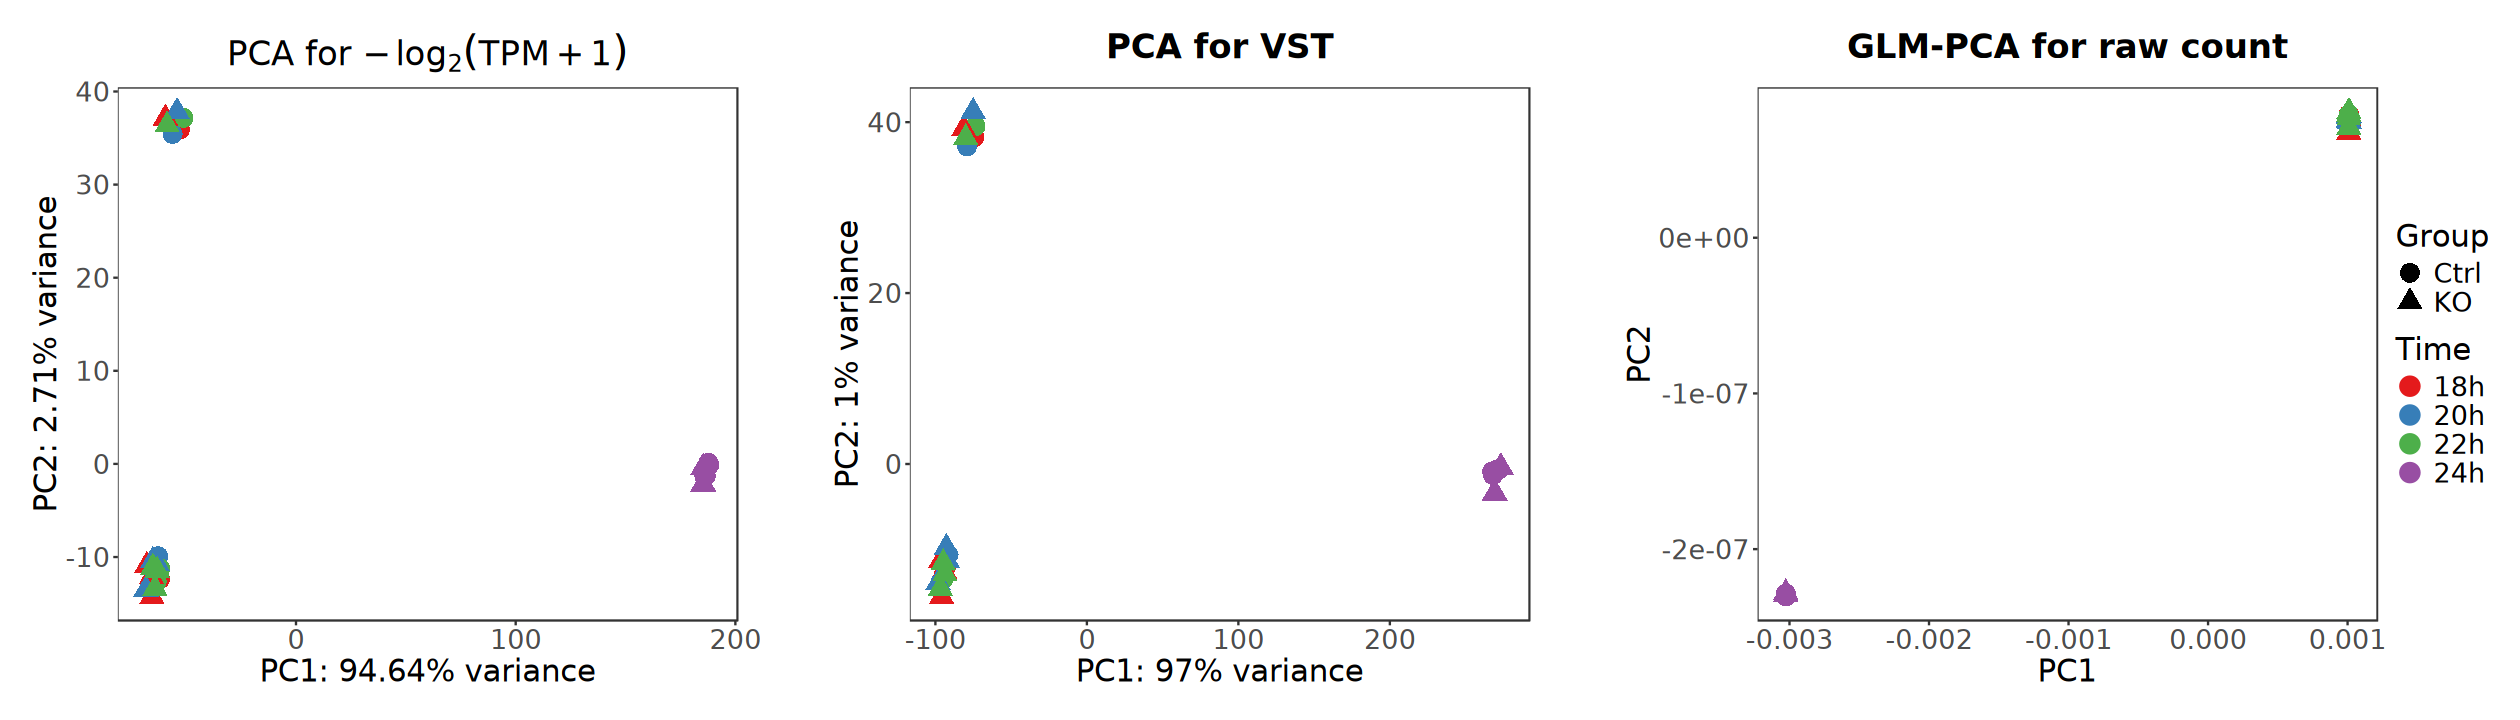

In [49]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [50]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

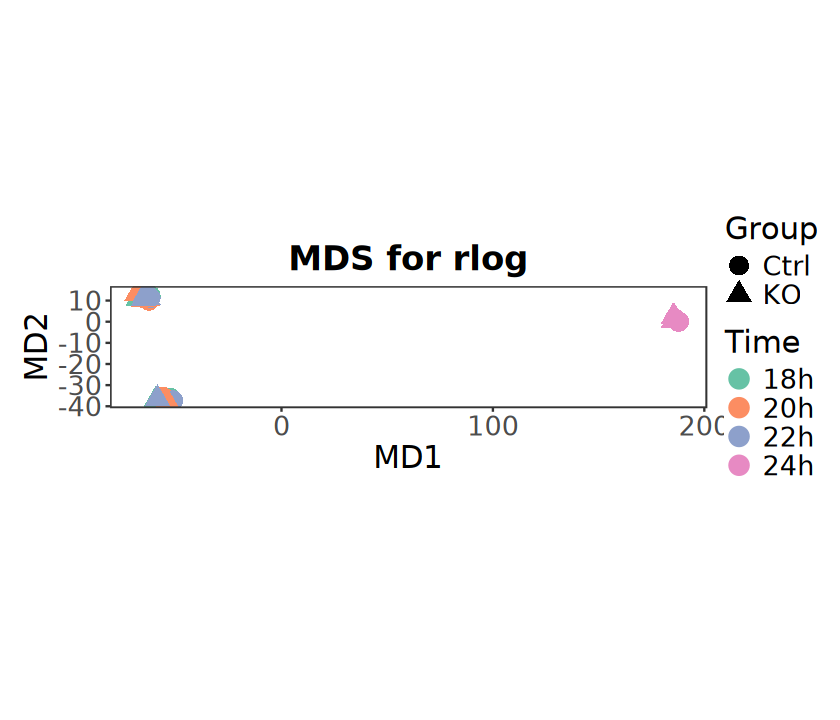

In [51]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    # geom_smooth(
    #     formula = "y ~ x", method = "loess", se = FALSE,
    #     color = "grey", linewidth = 1) +
    # geom_path(
    #     aes(group = 1), color = "black", 
    #     arrow = arrow(length = unit(0.15, "inches"))) +
    scale_color_brewer(palette = "Set2") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [52]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

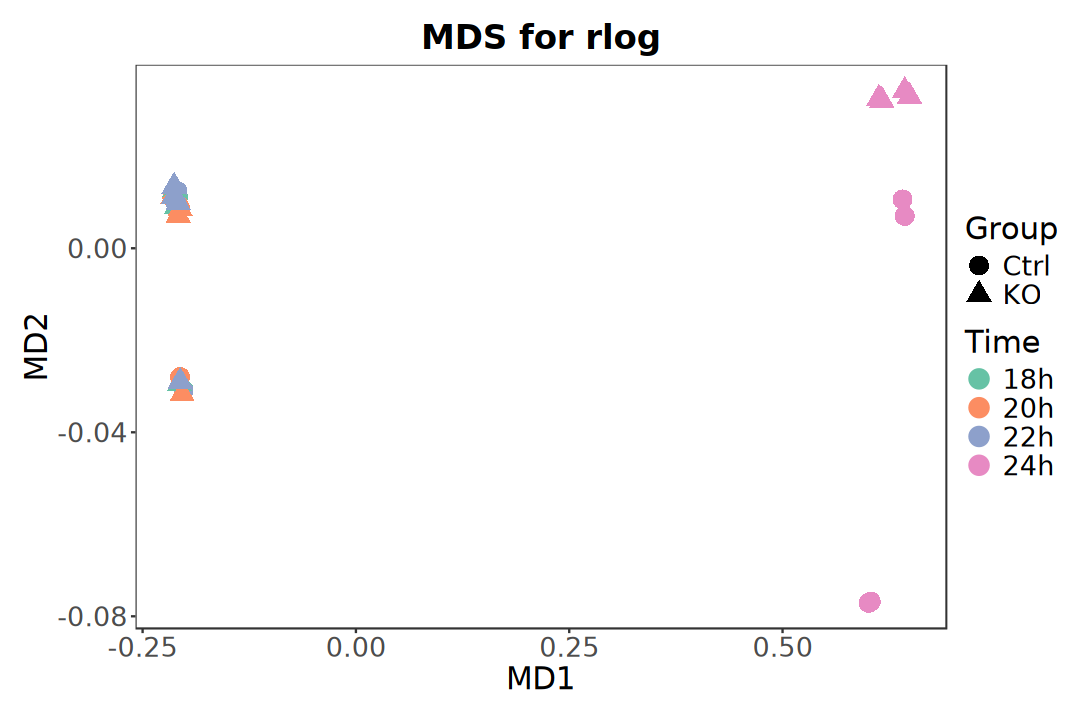

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2, color = Time, shape = Group)) +
    geom_point(size = 5) +
    # geom_smooth(
    #     formula = "y ~ x", method = "loess", se = FALSE,
    #     color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Correlation

In [54]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Time, Group)

In [55]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
time_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Time)),
    levels(eSet$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Time = time_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [56]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

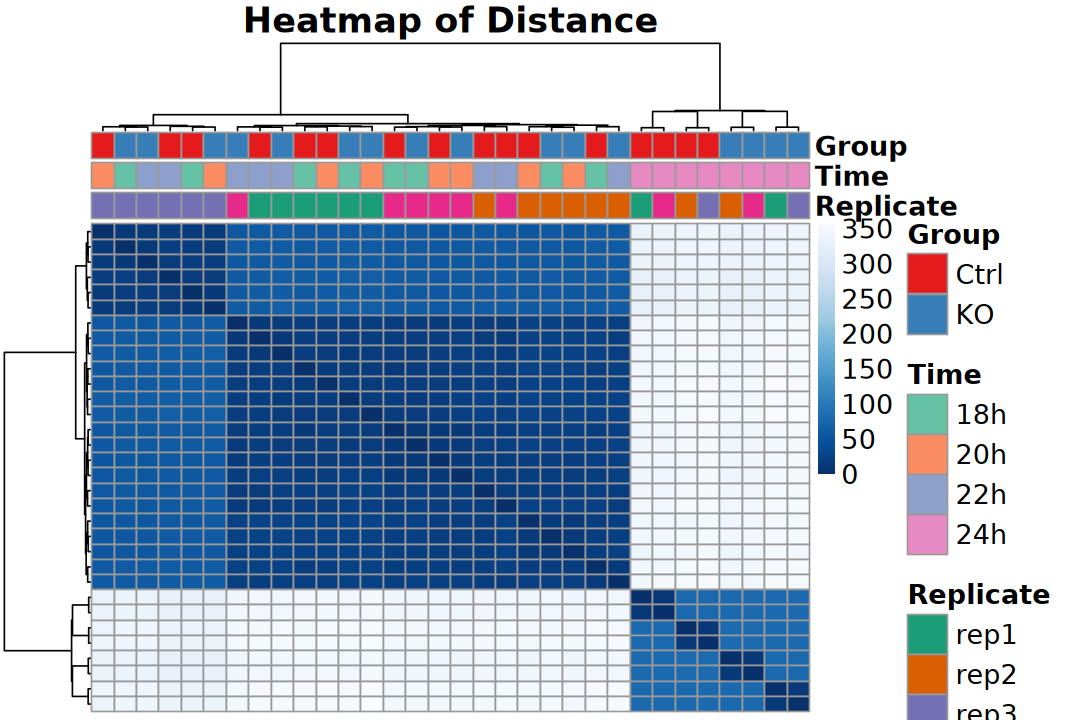

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [58]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

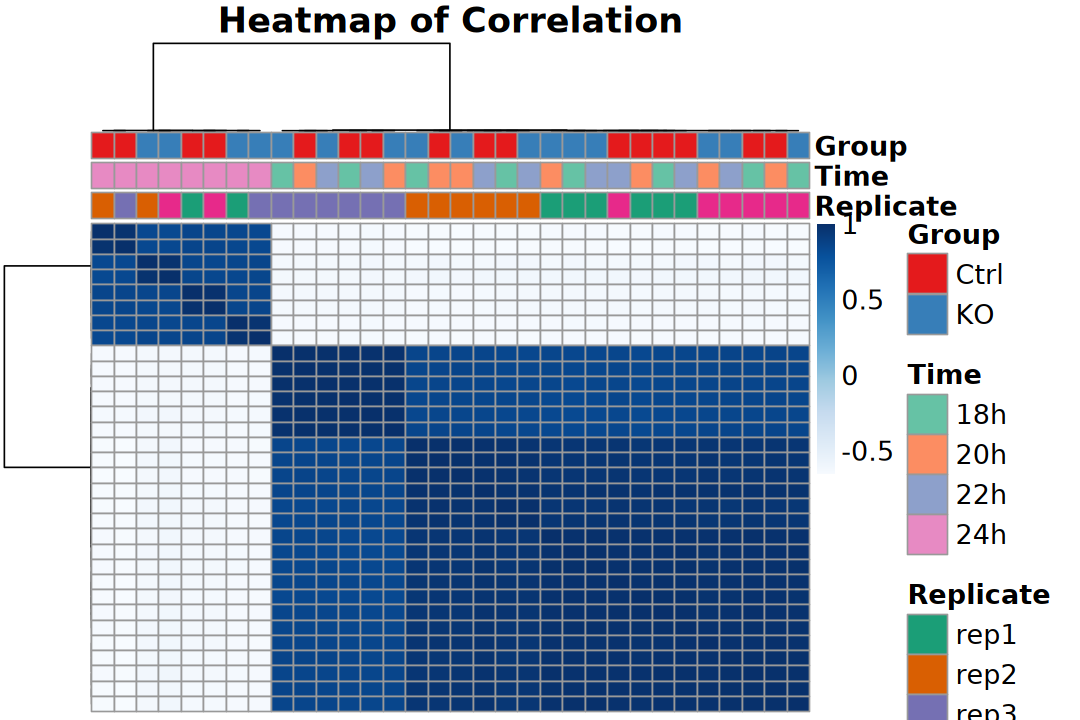

In [59]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

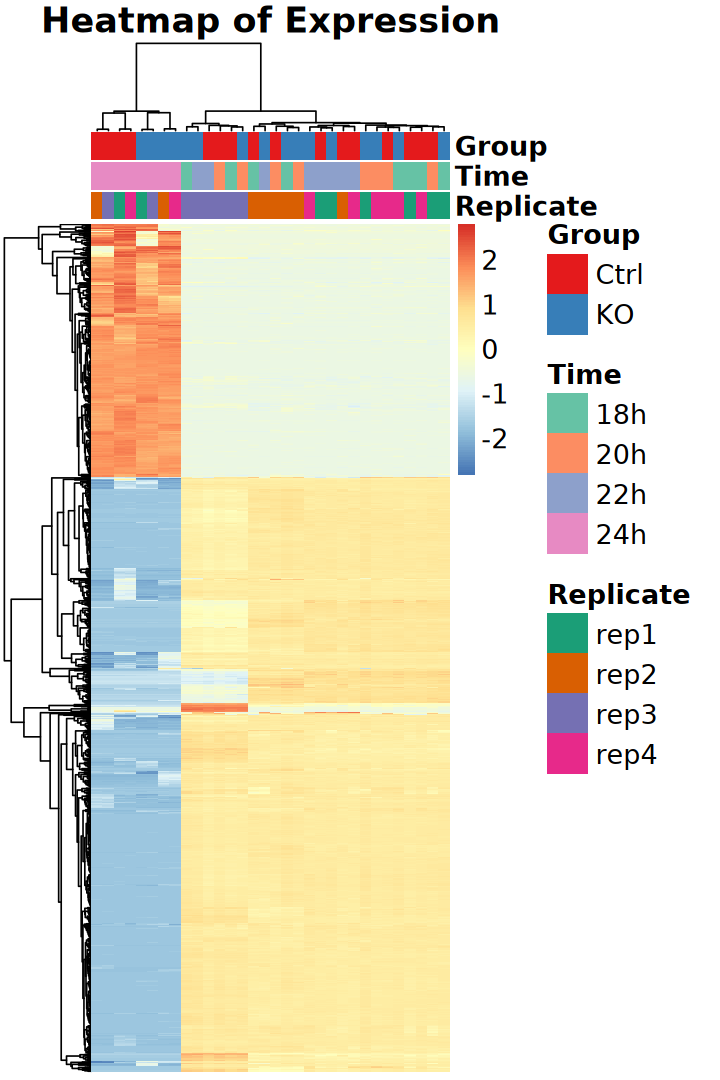

In [60]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)